# BS49903 · DS/AI for Biology
## Assignment 1 - SOLUTIONS

**Due: Friday, October 2, 11:59 PM**

**Instructions.** Work through the exercises in order. Fill in every cell marked `#### YOUR CODE HERE ####` and answer the written questions in the markdown cells provided. You may use any publicly available Python package unless instructed otherwise. Do not delete the cells that are given to you.


In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

%matplotlib inline

-----
## Part 1 — Why do we need Bessel's correction?

When we estimate the variance of a population from a sample, the textbook formula divides by $n-1$ instead of $n$:

$$
s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})^2
$$

Dividing by $n-1$ rather than $n$ is called **Bessel's correction**. In this part you will discover *experimentally* why it is needed.

The array `population` below contains **200 values** drawn from a Gaussian distribution. For the purposes of this exercise, treat these 200 values as the **entire population**.

In [2]:
population = np.array([
    53.0, 39.6, 57.5, 59.4, 30.5, 37.0, 51.3, 46.8, 49.8, 41.5,
    58.8, 57.8, 50.7, 61.3, 54.7, 41.4, 53.7, 40.4, 58.8, 49.5,
    48.2, 43.2, 62.2, 48.5, 45.7, 46.5, 55.3, 53.7, 54.1, 54.3,
    71.4, 45.9, 44.9, 41.9, 56.2, 61.3, 48.9, 41.6, 41.8, 56.5,
    57.4, 55.4, 43.3, 52.3, 51.2, 52.2, 58.7, 52.2, 56.8, 50.7,
    52.9, 56.3, 35.4, 46.8, 45.3, 43.6, 47.2, 64.9, 41.3, 59.7,
    33.2, 46.7, 51.6, 55.9, 57.1, 57.9, 46.5, 45.4, 58.6, 48.1,
    37.2, 38.7, 40.8, 55.0, 51.4, 56.9, 45.7, 51.6, 56.3, 46.9,
    54.6, 43.4, 46.4, 46.2, 38.0, 54.9, 45.3, 50.1, 54.8, 54.5,
    56.7, 49.0, 45.8, 49.2, 33.1, 35.5, 36.8, 40.0, 54.0, 40.9,
    46.2, 63.0, 46.4, 57.4, 40.7, 47.9, 40.5, 46.6, 58.4, 32.7,
    54.3, 52.4, 44.1, 35.5, 50.7, 44.7, 52.3, 50.2, 66.0, 47.6,
    39.8, 51.8, 52.2, 63.6, 58.4, 53.6, 64.6, 38.1, 43.6, 40.7,
    46.1, 36.2, 56.4, 47.8, 35.3, 39.8, 53.1, 58.4, 70.0, 79.1,
    54.1, 40.1, 28.7, 52.7, 41.9, 45.8, 43.9, 48.6, 60.7, 51.6,
    48.4, 39.6, 33.3, 45.1, 49.5, 67.7, 51.3, 59.8, 45.0, 38.2,
    40.3, 42.7, 71.3, 41.8, 58.4, 41.0, 59.3, 53.8, 48.4, 49.6,
    43.5, 54.5, 45.5, 37.7, 37.2, 51.7, 65.8, 51.6, 48.8, 52.9,
    63.1, 52.2, 45.9, 61.1, 54.3, 65.4, 51.8, 37.8, 36.3, 66.5,
    67.2, 48.2, 46.2, 64.6, 38.9, 41.1, 56.4, 46.1, 49.9, 48.4,
])

print("Population size:", len(population))

Population size: 200


### Exercise 1.1 (0.5 pts)

Compute the **mean** $\mu$ and the **standard deviation** $\sigma$ of the population.

Because this is the *whole* population, use the population formula (divide by $N$, not $N-1$):

$$
\mu = \frac{1}{N}\sum_{i=1}^{N} x_i, \qquad
\sigma = \sqrt{\frac{1}{N}\sum_{i=1}^{N}(x_i-\mu)^2}
$$

In [3]:
population_mean = population.mean()
population_std = population.std(ddof=0)   # ddof=0 is the default: divide by N

print(f"Population mean:               {population_mean:.4f}")
print(f"Population standard deviation: {population_std:.4f}")

Population mean:               49.6965
Population standard deviation: 8.7988


### Exercise 1.2 (1 pt)

Now imagine you could **not** see the whole population and could only afford to measure a sample of **30** individuals at a time.

1. Repeat the following **1000 times**: draw a random sample of size 30 from `population`, and compute the standard deviation of that sample using the **naive** formula that divides by $n$. Store all 1000 values.
2. Compute the **mean of the 1000 sample standard deviations**.
3. Do the same again, but this time compute each sample standard deviation with **Bessel's correction** (divide by $n-1$).
4. Print both means next to the true population standard deviation from Exercise 1.1.

Use the random generator `rng` defined below so that your results are reproducible.

The line that draws one sample is given to you:

```python
sample = rng.choice(population, size=sample_size, replace=False)
```

In [4]:
rng = np.random.default_rng(seed=0)

sample_size = 30
n_repeats = 1000

In [5]:
sample_stds_naive = []      
sample_stds_bessel = []     

for i in range(n_repeats):
    # draw one random sample of `sample_size` individuals from the population
    sample = rng.choice(population, size=sample_size, replace=False)

    sample_stds_naive.append(sample.std(ddof=0))    # divide by n
    sample_stds_bessel.append(sample.std(ddof=1))   # divide by n-1

mean_std_naive = np.mean(sample_stds_naive)
mean_std_bessel = np.mean(sample_stds_bessel)

print(f"True population std:                       {population_std:.4f}")
print(f"Mean of sample stds (divide by n):         {mean_std_naive:.4f}")
print(f"Mean of sample stds (divide by n-1):       {mean_std_bessel:.4f}")

True population std:                       8.7988
Mean of sample stds (divide by n):         8.6127
Mean of sample stds (divide by n-1):       8.7600


### Exercise 1.3 (1 pt)

Compare the two means you obtained in Exercise 1.2 with the true population standard deviation.

1. How does the mean of the sample standard deviations computed with the naive formula (divide by $n$) compare with the population standard deviation?
2. Does Bessel's correction (divide by $n-1$) fix the problem?

**Solution.** 1. The naive estimate (divide by $n$) is **systematically too low**: averaged over the 1000 samples it gives about 8.61, versus the true $\sigma \approx 8.80$. This is a *bias*, not random noise — it stays in the same direction no matter how many repetitions you run. The reason is that the sample mean $\bar{x}$ is computed from the same points, and $\bar{x}$ is exactly the value that minimises $\sum (x_i - c)^2$; the deviations from $\bar{x}$ are therefore on average smaller than the deviations from the true mean $\mu$.

2. **Yes, essentially.** Dividing by $n-1$ gives a mean of about 8.76, very close to 8.80. Bessel's correction makes the sample **variance** exactly unbiased ($E[s^2] = \sigma^2$). The standard deviation $s = \sqrt{s^2}$ still has a tiny downward bias (the square root is concave), which is why the corrected value lands slightly below $\sigma$ rather than exactly on it — but the large, systematic underestimate is gone.

-----
## Part 2 — Linear regression with the Palmer penguins

The file `penguins.csv` contains measurements of 344 penguins from three species (Adelie, Chinstrap and Gentoo) observed on islands in the Palmer Archipelago, Antarctica. We will use it to study the relationship between **bill depth** and **body mass**.

### Exercise 2.1 (0.5 pts)

Use `pandas` to read `data/penguins.csv` into a DataFrame called `penguins` and display the **first 10 rows**.

In [6]:
penguins = pd.read_csv("data/penguins.csv")
penguins.head(10)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,FEMALE
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,MALE
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN


Some rows contain missing values (`NaN`). Run the cell below to drop the rows that are missing either of the two columns we care about.

In [7]:
penguins = penguins.dropna(subset=["bill_depth_mm", "body_mass_g"]).reset_index(drop=True)
print("Rows after dropping missing values:", len(penguins))

Rows after dropping missing values: 342


### Exercise 2.2 (1 pt)

The scatter plot below shows **bill depth (mm)** on the $x$-axis and **body mass (g)** on the $y$-axis.

1. Fit a simple linear regression model
   $$\text{body\_mass\_g} = b_0 + b_1 \cdot \text{bill\_depth\_mm}$$
   to the whole dataset.
2. Write down the coefficients $b_0$ (intercept) and $b_1$ (slope) that you obtained by **typing them into the cell after the plot**. The plotting code in that cell will draw the corresponding line on top of the scatter plot for you.
3. Report your $b_0$ and $b_1$ values in the markdown cell provided.

First, run the cell below to look at the data.

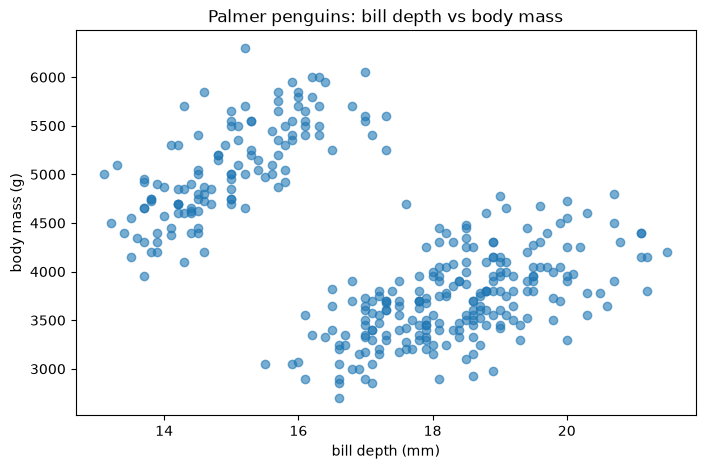

In [8]:
x = penguins["bill_depth_mm"].to_numpy()
y = penguins["body_mass_g"].to_numpy()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, alpha=0.6)
ax.set_xlabel("bill depth (mm)")
ax.set_ylabel("body mass (g)")
ax.set_title("Palmer penguins: bill depth vs body mass")
plt.show()

Fit the model here:

In [9]:
model = LinearRegression()
model.fit(x.reshape(-1, 1), y)      # sklearn expects a 2-D feature matrix

b0 = model.intercept_   # intercept
b1 = model.coef_[0]     # slope

print(f"b0 (intercept) = {b0:.2f}")
print(f"b1 (slope)     = {b1:.2f}")

b0 (intercept) = 7488.65
b1 (slope)     = -191.64


Now **type your coefficients** into the cell below and run it. The fitted line will be drawn on top of the scatter plot.

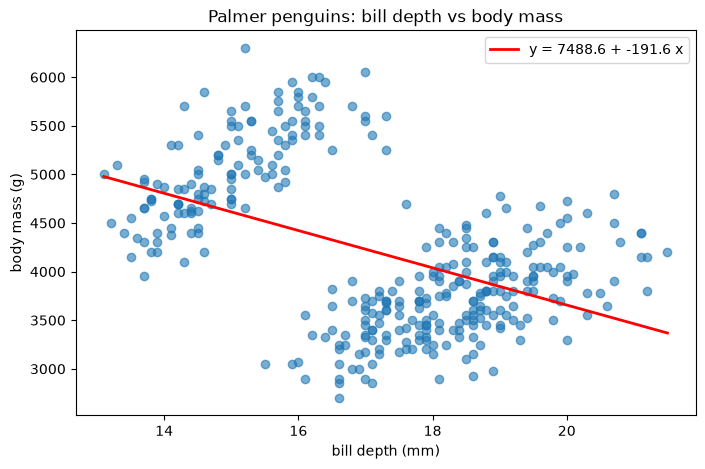

In [10]:
# Type in the coefficients you obtained above
my_b0 = 7488.65
my_b1 = -191.64

# scatter plot of the data
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, alpha=0.6)

# draw the line y = my_b0 + my_b1 * x over the range of bill depths in the data
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, my_b0 + my_b1 * xs, color="red", linewidth=2,
        label=f"y = {my_b0:.1f} + {my_b1:.1f} x")

ax.set_xlabel("bill depth (mm)")
ax.set_ylabel("body mass (g)")
ax.set_title("Palmer penguins: bill depth vs body mass")
ax.legend()
plt.show()


**Solution.** - $b_0 \approx 7488.65$ g
- $b_1 \approx -191.64$ g/mm

Note the **negative** slope: this model says penguins with deeper bills are *lighter*. (Equivalent: `np.polyfit(x, y, 1)` gives the same numbers.)

### Exercise 2.3 (1 pt)

Look carefully at the plot you produced in Exercise 2.2, then run the cell below, which shows the **same** scatter plot but coloured by species.

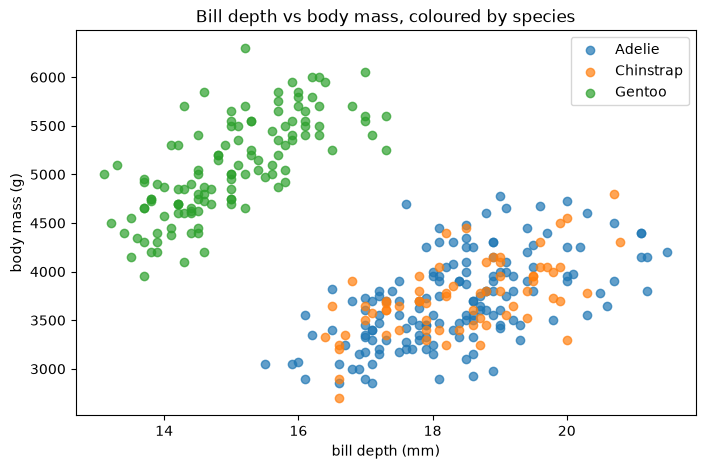

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
for species, group in penguins.groupby("species"):
    ax.scatter(group["bill_depth_mm"], group["body_mass_g"], alpha=0.7, label=species)
ax.set_xlabel("bill depth (mm)")
ax.set_ylabel("body mass (g)")
ax.set_title("Bill depth vs body mass, coloured by species")
ax.legend()
plt.show()


Answer the following in the markdown cell below.

1. Is the single linear model from Exercise 2.2 good for predicting body mass from bill depth? Does the sign of $b_1$ make biological sense? What do the data look like *within* each species compared to the trend across *all* penguins?
2. How could you improve the model using the species information? You may use multiple models if necessary.

**Solution.** 1. **No, the single model is poor.** Its $R^2$ is only about 0.22, and more importantly the slope is *negative*, which does not make biological sense: within each species, deeper bills clearly go with *heavier* birds (positive trend). The negative pooled slope is an artefact of the fact that Gentoo penguins are both much heavier (~5000 g vs ~3700 g) *and* have much shallower bills (~15 mm vs ~18.4 mm) than the other two species. Pooling the groups mixes a between-species difference with the within-species relationship — a classic **Simpson's paradox**. Predictions would be badly biased for every species.

2. **Use species as a grouping variable and fit separate regressions.** The coloured plot shows two clearly separated clusters: Gentoo (shallow bills, heavy) and Adelie + Chinstrap (deep bills, lighter). Adelie and Chinstrap overlap almost completely, so they can share a model; Gentoo needs its own. Concretely: fit one line on the Gentoo rows and one on the Adelie + Chinstrap rows, each with its own intercept and slope. Fitting three models (one per species) is equally acceptable, as is a single multiple regression with a species dummy variable and a species × bill-depth interaction term — all of these let the slope differ between groups.

### Exercise 2.4 (1.5 pts)

Implement the strategy you described in Exercise 2.3. Explain how the new model(s) perform compared with the model from Exercise 2.2.

  single model (all species):  b0 =   7488.65   b1 =  -191.64   R^2 = 0.223
                      Gentoo:  b0 =   -458.99   b1 =   369.44   R^2 = 0.517
          Adelie + Chinstrap:  b0 =   -217.20   b1 =   213.83   R^2 = 0.340


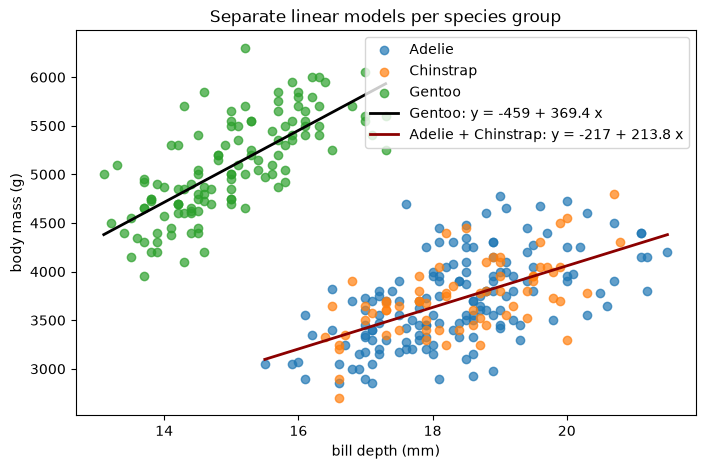

In [12]:
groups = {
    "Gentoo": penguins[penguins["species"] == "Gentoo"],
    "Adelie + Chinstrap": penguins[penguins["species"].isin(["Adelie", "Chinstrap"])],
}
colors = {"Gentoo": "black", "Adelie + Chinstrap": "darkred"}

# R^2 of the single pooled model from Exercise 2.2, for comparison
r2_pooled = LinearRegression().fit(x.reshape(-1, 1), y).score(x.reshape(-1, 1), y)
print(f"{'single model (all species)':>28s}:  b0 = {b0:9.2f}   b1 = {b1:8.2f}   R^2 = {r2_pooled:.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
for species, group in penguins.groupby("species"):
    ax.scatter(group["bill_depth_mm"], group["body_mass_g"], alpha=0.7, label=species)

for name, group in groups.items():
    xg = group["bill_depth_mm"].to_numpy()
    yg = group["body_mass_g"].to_numpy()

    model_g = LinearRegression().fit(xg.reshape(-1, 1), yg)
    b0_g = model_g.intercept_
    b1_g = model_g.coef_[0]
    r2_g = model_g.score(xg.reshape(-1, 1), yg)
    print(f"{name:>28s}:  b0 = {b0_g:9.2f}   b1 = {b1_g:8.2f}   R^2 = {r2_g:.3f}")

    xs = np.linspace(xg.min(), xg.max(), 100)
    ax.plot(xs, b0_g + b1_g * xs, color=colors[name], linewidth=2,
            label=f"{name}: y = {b0_g:.0f} + {b1_g:.1f} x")

ax.set_xlabel("bill depth (mm)")
ax.set_ylabel("body mass (g)")
ax.set_title("Separate linear models per species group")
ax.legend()
plt.show()

**Solution.** Both group-specific slopes are now **positive** (Gentoo ≈ +369 g/mm, Adelie + Chinstrap ≈ +214 g/mm): within each group, deeper bills go with heavier penguins, which is biologically sensible. The fit also improves substantially — $R^2 \approx 0.52$ for Gentoo and $\approx 0.34$ for Adelie + Chinstrap, versus $\approx 0.22$ for the pooled model, which was additionally predicting in the *wrong direction*. Conditioning on species removes the confounding and turns a misleading model into a useful one.

If three separate models are fitted instead, the reference values are: Adelie $b_1 \approx +217$, Chinstrap $b_1 \approx +205$, Gentoo $b_1 \approx +369$ (all positive).

-----

## Part 3 — Linear regression on fMRI time-series data

The file `fmri_bold.csv` contains BOLD signals measured with fMRI. Each row is one subject in one experimental condition, and the columns `t0 … t18` contain the measured signal at each of 19 successive time points.

We will use a single condition: the response of the parietal region to the stimulus, measured in 14 subjects.


In [13]:
df = pd.read_csv("data/fmri_bold.csv")
tcols = [c for c in df.columns if c.startswith("t")]

sub = df[(df.event == "stim") & (df.region == "parietal")]
bold = sub[tcols].to_numpy()        # shape (14, 19): 14 subjects x 19 time points
subjects = sub["subject"].tolist()

print("BOLD matrix shape:", bold.shape)
print("Subjects:", subjects)


BOLD matrix shape: (14, 19)
Subjects: ['s0', 's1', 's2', 's3', 's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13']


Each of the 14 subjects gives us 19 measurements, one per time point. We treat every measurement as one data point $(t_i, y_i)$, where $t$ is the time point index and $y$ is the BOLD value. That gives $14 \times 19 = 266$ points in total.

Run the cell below to build the two arrays `t` and `y` and look at the data.

Number of points: 266


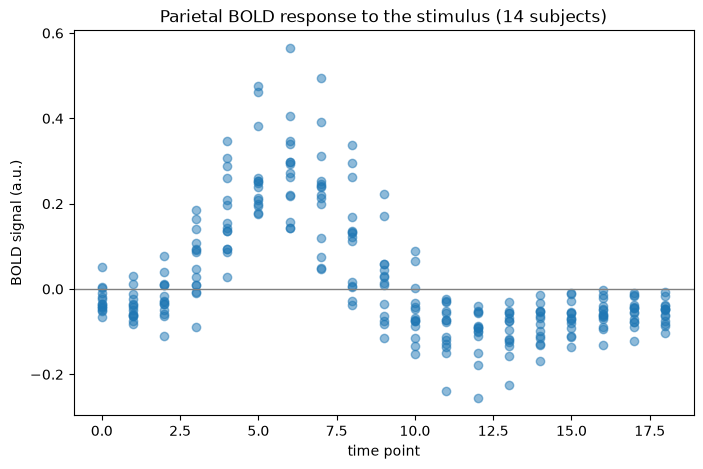

In [14]:
n_subjects, n_times = bold.shape

t = np.tile(np.arange(n_times), n_subjects).astype(float)   # 0,1,...,18, 0,1,...,18, ...
y = bold.ravel()                                            # the matching BOLD values

print("Number of points:", len(t))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(t, y, alpha=0.5)
ax.axhline(0, color="gray", linewidth=1)
ax.set_xlabel("time point")
ax.set_ylabel("BOLD signal (a.u.)")
ax.set_title("Parietal BOLD response to the stimulus (14 subjects)")
plt.show()


### Exercise 3.1 (1 pt)

Fit the simplest possible model, using **only $t$** as a feature:

$$
y = b_0 + b_1 \, t
$$

1. Fit the model to all 266 points.
2. Print $b_0$, $b_1$ and the $R^2$ of the fit.
3. Run the plotting code that follows to draw the fitted line on top of the data.

b0 = 0.1178   b1 = -0.0108   R^2 = 0.1693


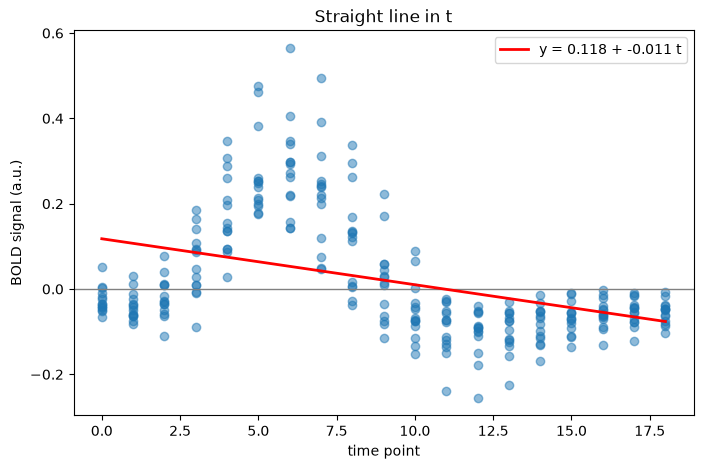

In [15]:
model_lin = LinearRegression().fit(t.reshape(-1, 1), y)

b0_lin = model_lin.intercept_                       # intercept
b1_lin = model_lin.coef_[0]                         # slope
r2_lin = model_lin.score(t.reshape(-1, 1), y)       # R^2

print(f"b0 = {b0_lin:.4f}   b1 = {b1_lin:.4f}   R^2 = {r2_lin:.4f}")

# plot the data and the fitted line
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(t, y, alpha=0.5)
ax.axhline(0, color="gray", linewidth=1)

ts = np.linspace(t.min(), t.max(), 200)
ax.plot(ts, b0_lin + b1_lin * ts, color="red", linewidth=2,
        label=f"y = {b0_lin:.3f} + {b1_lin:.3f} t")

ax.set_xlabel("time point")
ax.set_ylabel("BOLD signal (a.u.)")
ax.set_title("Straight line in t")
ax.legend()
plt.show()

**Solution.** $b_0 \approx 0.1178$, $b_1 \approx -0.0108$, $R^2 \approx 0.169$. The straight line captures only the slow overall decrease and misses the rise-and-fall shape of the response.

### Exercise 3.2 (1 pt)

Does the model from Exercise 3.1 fit the BOLD response? Let us give the model more freedom by adding **$t^2$ and $t^3$ as extra features**:

$$
y = b_0 + b_1 t + b_2 t^2 + b_3 t^3
$$

This is **still a linear regression model**: it is linear in the *parameters* $b_0, \dots, b_3$, even though it is a curve in $t$. Fitting it is exactly the same procedure as before — we simply hand the model three feature columns instead of one.

Build the feature matrix with

```python
features = np.column_stack([t, t**2, t**3])   # shape (266, 3)
```

1. Fit the model on `features` and print $b_0, b_1, b_2, b_3$ and the $R^2$.
2. The plotting code below your fit will draw the line for you.
3. Compare the $R^2$ with the one from Exercise 3.1.

b0 = -0.1150   b1 = 0.1357   b2 = -0.0185   b3 = 0.00063
R^2 = 0.5613   (straight line was 0.1693)


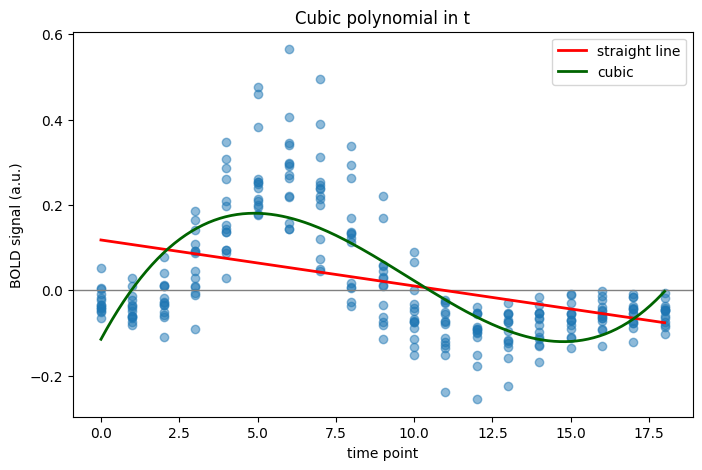

In [16]:
features = np.column_stack([t, t**2, t**3]) # 266 x 3 matrix of features (t, t^2, t^3)

model_cub = LinearRegression().fit(features, y)

b0_cub = model_cub.intercept_                 # intercept
b1_cub, b2_cub, b3_cub = model_cub.coef_      # the three coefficients
r2_cub = model_cub.score(features, y)         # R^2

print(f"b0 = {b0_cub:.4f}   b1 = {b1_cub:.4f}   b2 = {b2_cub:.4f}   b3 = {b3_cub:.5f}")
print(f"R^2 = {r2_cub:.4f}   (straight line was {r2_lin:.4f})")

# plot the data and the fitted curve
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(t, y, alpha=0.5)
ax.axhline(0, color="gray", linewidth=1)

ts = np.linspace(t.min(), t.max(), 200)
ax.plot(ts, b0_lin + b1_lin * ts, color="red", linewidth=2, label="straight line")
ax.plot(ts, b0_cub + b1_cub * ts + b2_cub * ts**2 + b3_cub * ts**3,
        color="darkgreen", linewidth=2, label="cubic")

ax.set_xlabel("time point")
ax.set_ylabel("BOLD signal (a.u.)")
ax.set_title("Cubic polynomial in t")
ax.legend()
plt.show()

Compare the two models. Which one describes the shape of the BOLD response better, and what does the $R^2$ tell you? Is the cubic model still a *linear* model, and why?

**Solution.** Reference values: $b_0 \approx -0.1150$, $b_1 \approx 0.1357$, $b_2 \approx -0.0185$, $b_3 \approx 0.00063$, $R^2 \approx 0.561$ (vs. 0.169 for the straight line).

**Which fits better.** The cubic model describes the BOLD response far better: it reproduces the characteristic shape — a rise to a peak a few time points after the stimulus, followed by a decay and a dip below baseline — whereas the straight line can only express a monotonic drift. The $R^2$ jumps from about 0.17 to about 0.56, meaning the cubic explains more than half of the variance in the signal, compared with less than a fifth for the line. (The remaining variance is mostly between-subject variability at each time point, which no function of $t$ alone can capture.)

**Is it still linear?** Yes. "Linear regression" means the model is linear in the **parameters** $b_0, \dots, b_3$: the prediction is a weighted sum $b_0 \cdot 1 + b_1 \cdot t + b_2 \cdot t^2 + b_3 \cdot t^3$ of fixed feature columns. The features themselves ($t^2$, $t^3$) are non-linear functions of $t$, but from the model's point of view they are just three more input columns. That is why the same `LinearRegression` fit — and the same closed-form least-squares solution — works unchanged.

### Exercise 3.3 (1.5 pts)

If $X$ is the design matrix (one row per data point, one column per feature) and $y$ the vector of targets, the least-squares solution is

$$
\hat{\beta} = (X^\top X)^{-1} X^\top y
$$

In this exercise you will compute this **without using `scikit-learn`**, for the same cubic model as in Exercise 3.2.

**Building $X$.** The intercept $b_0$ is not special — it is just the coefficient of a feature that is always equal to 1. So the design matrix must have a **column of ones** as its first column:

$$
X = \begin{bmatrix}
1 & t_1 & t_1^2 & t_1^3 \\
1 & t_2 & t_2^2 & t_2^3 \\
\vdots & \vdots & \vdots & \vdots \\
1 & t_n & t_n^2 & t_n^3
\end{bmatrix}
$$

so `X` has shape $(266, 4)$ and $\hat{\beta}$ has 4 entries: $[b_0, b_1, b_2, b_3]$.

**Computing a matrix inverse.** The inverse $A^{-1}$ of a square matrix `A` is computed with

```python
np.linalg.inv(A)
```

1. Build the design matrix `X` with the four columns above.
2. Compute $\hat{\beta}=(X^\top X)^{-1} X^\top y$ to get the coefficients.
3. Print the four coefficients and check that they match what `scikit-learn` gave you in Exercise 3.2.

beta = [-0.1149836   0.13569652 -0.01845274  0.00062559]
b0 = -0.1150   b1 = 0.1357   b2 = -0.0185   b3 = 0.00063
max |difference| vs scikit-learn: 1.84297022087776e-14


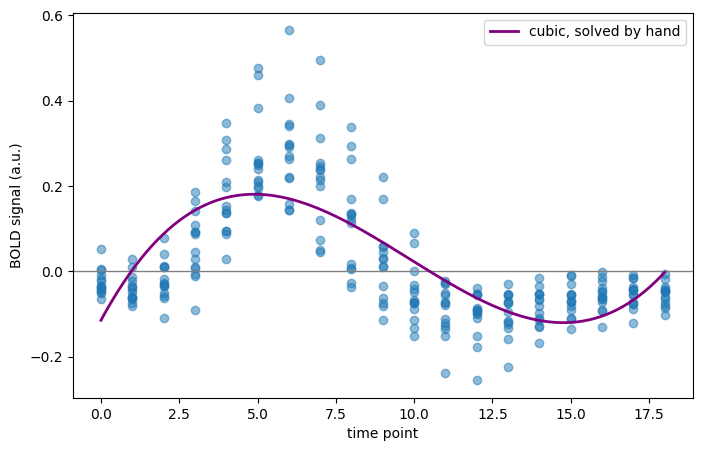

In [17]:
n = len(t)

X = np.column_stack([np.ones(n), t, t**2, t**3])   # design matrix, shape (266, 4)
beta = np.linalg.inv(X.T @ X) @ X.T @ y            # normal equations

print("beta =", beta)
print(f"b0 = {beta[0]:.4f}   b1 = {beta[1]:.4f}   b2 = {beta[2]:.4f}   b3 = {beta[3]:.5f}")

# check against scikit-learn
sk = np.array([b0_cub, b1_cub, b2_cub, b3_cub])
print("max |difference| vs scikit-learn:", np.abs(beta - sk).max())

y_hat = X @ beta          # predictions for the data points

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(t, y, alpha=0.5)
ax.axhline(0, color="gray", linewidth=1)

ts = np.linspace(t.min(), t.max(), 200)
Xs = np.column_stack([np.ones(len(ts)), ts, ts**2, ts**3])
ax.plot(ts, Xs @ beta, color="purple", linewidth=2, label="cubic, solved by hand")

ax.set_xlabel("time point")
ax.set_ylabel("BOLD signal (a.u.)")
ax.legend()
plt.show()

Did your hand-computed coefficients match the results using `scikit-learn`?

**Solution.** Yes. $\hat\beta = (X^\top X)^{-1} X^\top y$ gives $[-0.1150,\ 0.1357,\ -0.0185,\ 0.00063]$, identical to the scikit-learn coefficients up to floating-point round-off (differences of order $10^{-12}$ or smaller). This is expected: `LinearRegression` solves exactly the same least-squares problem, just with a numerically more careful algorithm (a least-squares solver rather than an explicit matrix inverse). The purple curve therefore lies exactly on top of the green cubic from Exercise 3.2.